# Notebook 02 — Preparación y selección de series de precipitación diaria DHIME

**TFM:** Evaluación de la influencia del componente espacial en la estimación de datos faltantes de precipitación diaria mediante modelos de Machine Learning aplicados a estaciones meteorológicas.

Este notebook toma como entrada las **(estaciones candidatas)** seleccionadas en el **"Notebook 01"** e integra los registros de precipitación diaria obtenidos manualmente desde la plataforma DHIME del IDEAM.

El objetivo es evaluar la disponibilidad temporal de las series, identificar datos faltantes, analizar el solapamiento entre estaciones e incorporar información espacial para seleccionar el periodo y el conjunto de estaciones que se utilizarán posteriormente en el experimento de imputación.

La salida del notebook conservará los valores faltantes naturales de las series seleccionadas. La simulación controlada de datos faltantes y la división de los datos para entrenamiento y evaluación se realizarán en el **Notebook 03**.



---



## 1 - Objetivo del notebook

Este notebook toma como entrada los registros historicos de precipitación de las estaciones candidatas generadas en el **Notebook 01**. Se evalurá un periodo de tiempo con datos de precipitación registrados que se compartan entre varias estaciones.

La salida principal será:

```text
data/raw/precipitación/(archivo por estación).zip
```

y, como respaldo:

```text
data/intermediate/precipitacion_periodo_seleccionado.parquet
```

Estos archivos serán usados en el **Diseño Experimental para Imputación de Precipitación Diaria**.



### 1.1 - Flujo de este notebook

```text
estaciones_candidatas.zip
        ↓
descargar precipitación desde DHIME por estación
        ↓
guardar registros crudos de precipitación
        ↓
generar log de descarga y resumen por estación
```

### 1.2 Importar librerías y definir carpetas del proyecto

La estructura de carpetas esperada es:

```text
TFM_precipitacion/
├── data/
│   ├── raw/
│   ├── interim/
│   └── processed/
├── outputs/
│   ├── tables/
│   ├── figures/
│   └── logs/
└── notebooks/
```

A continuación, descargamos las librerias requeridas para el desarrollo del presente Notebook

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

A continuación se verifica la estructura de archivos que maneja el proyecto, se identifica la carpeta raíz junto con la estructura de directorios utilizada por los notebooks. Esto evita depender de rutas absolutas y permite mantener separados los datos crudos, intermedios, procesados y los productos de salida.

In [4]:
from pathlib import Path

carpeta_actual = Path.cwd()

if carpeta_actual.name == 'notebooks':
    PROJECT_ROOT = carpeta_actual.parent
else:
    PROJECT_ROOT = carpeta_actual

folders = [
    PROJECT_ROOT / "data" / "raw"/ "precipitacion",
    PROJECT_ROOT / "data" / "intermediate",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "output" / "tables",
    PROJECT_ROOT / "output" / "figures",
    PROJECT_ROOT / "scr"
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

## 2 - Lectura del índice de estaciones candidatas

La descarga de los archivos de la plataforma **DHIME** se hace de manera manual dentro de la [Plataforma](https://atencionciudadano.ideam.gov.co/), para lo cual se requiere lo siguiente:



*   Variable (Tipo de estación) = Precipitación
*   Departamento
*   Municipio
*   Código de la estación (Proviene del Notebook 1)
*   Priodo = Desde el año 2000 a 2024



  En los archivos anexos del TFM se entrega la documentación oficial para la descarga de los registros.

A continuación, se define la ruta del archivo `estaciones_candidatas.geojson`, generado en el Notebook 01, siendo este la entrada espacial del Notebook 02 y contiene las estaciones candidatas junto con sus atributos y geometría.

In [5]:
# Archivo generado por el Notebook 01
ESTACIONES_CANDIDATAS_PATH =  PROJECT_ROOT / "data" / "raw" / "estaciones_candidatas.geojson"

A Continuación creamos el Geo DataFrame con la salida del Notebook 1

In [6]:
estaciones_candidatas = gpd.read_file(ESTACIONES_CANDIDATAS_PATH)
estaciones_candidatas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 35 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   CODIGO          19 non-null     object        
 1   nombre          19 non-null     object        
 2   CATEGORIA       19 non-null     object        
 3   TECNOLOGIA      19 non-null     object        
 4   ESTADO          19 non-null     object        
 5   FECHA_INST      19 non-null     datetime64[ms]
 6   altitud         19 non-null     float64       
 7   latitud         19 non-null     float64       
 8   longitud        19 non-null     float64       
 9   DEPARTAMEN      19 non-null     float64       
 10  MUNICIPIO       19 non-null     float64       
 11  AREA_OPERA      19 non-null     float64       
 12  AREA_HIDRO      19 non-null     float64       
 13  ZONA_HIDRO      19 non-null     float64       
 14  CORRIENTE       19 non-null     float64       
 15  

Para que la descarga manual en la plataforma del DHIME sea más sencilla, se necesita extraen del catálogo los nombres de las estaciones y su localización administrativa. La selección se transforma en una lista de Python que puede consultarse directamente durante el proceso de descarga.

In [7]:
lista_estacion_CodNombre = estaciones_candidatas[["nombre","d_DEPARTAM","d_MUNICIPI"]].to_numpy().tolist() # https://docs.kanaries.net/es/topics/Pandas/dataframe-to-list
lista_estacion_CodNombre


[['UNIV PEDAGOGICA [21206190]', 'Bogotá', 'Bogota, D.C'],
 ['SOLMAFORO BOGOTA - [21205529]', 'Bogotá', 'Bogota, D.C'],
 ['BOMBEROS DEL NORTE [21205800]', 'Bogotá', 'Bogota, D.C'],
 ['JARDIN BOTANICO [21205710]', 'Bogotá', 'Bogota, D.C'],
 ['ESAP [21206040]', 'Bogotá', 'Bogota, D.C'],
 ['UNIVERSIDAD NACIONAL [21205012]', 'Bogotá', 'Bogota, D.C'],
 ['EDIFICIO PREMIUM [21206540]', 'Bogotá', 'Bogota, D.C'],
 ['SOLMAFORO BOGOTA - [21205528]', 'Bogotá', 'Bogota, D.C'],
 ["ENMANUEL D' ALZON [21201230]", 'Bogotá', 'Bogota, D.C'],
 ['OBS MET NACIONAL [21205230]', 'Bogotá', 'Bogota, D.C'],
 ['MOLINOS DEL NORTE [21206150]', 'Bogotá', 'Bogota, D.C'],
 ['VELODROMO 1 D MAYO [21205600]', 'Bogotá', 'Bogota, D.C'],
 ['ADPOSTAL [21206000]', 'Bogotá', 'Bogota, D.C'],
 ['IDEAM PUENTE ARANDA [2120500204]', 'Bogotá', 'Bogota, D.C'],
 ['LICORERA BOGOINAMA [21205820]', 'Bogotá', 'Bogota, D.C'],
 ['CENTRO MED ANDES [21205730]', 'Bogotá', 'Bogota, D.C'],
 ['SEDE IDEAM CALLE 25D KRA [21202280]', 'Bogotá', 'Bogot

La salida presenta las estaciones candidatas junto con departamento y municipio. Esta lista actúa como apoyo operativo para localizar en DHIME las estaciones definidas previamente y descargar sus series de precipitación.

Una vez descargados los registros de precipitación, los guardamos en la carpeta de:

```text
data/raw/precipitación/(archivo por estación).zip
```


## 3 - Importación de los archivos de precipitación DHIME

Se define la carpeta donde se almacenaron los archivos ZIP descargados desde DHIME y se listan los archivos existentes. Esta comprobación permite verificar, antes de importarlos, qué estaciones cuentan efectivamente con archivos disponibles en la carpeta de datos crudos.

In [8]:
RUTA_PRECIPITACION = PROJECT_ROOT / "data" / "raw"/ "precipitacion"

for archivo in RUTA_PRECIPITACION.iterdir():
  if archivo.is_file():
    print(archivo.name)


21206000.zip
21205230.zip
2120500204.zip
21202280.zip
21205012.zip
21206700.zip
21201230.zip
21205730.zip
21206190.zip
21205600.zip
21206540.zip
21206040.zip
21201600.zip
21205820.zip
21205710.zip
21206150.zip


La salida muestra los nombres de los archivos ZIP encontrados. Se observa que no todas las estaciones candidatas del Notebook 01 necesariamente cuentan con una descarga disponible, por lo que la comprobación posterior debe basarse en los códigos contenidos en los archivos y no únicamente en sus nombres.

A continuación, se creará un DataFrame que contenga todo lo anteriomente importado. Para lo anterior, se define la función `cargar_archivos_precipitacion()`. La función recorre cada archivo ZIP, identifica los CSV contenidos en su interior, los lee y concatena todos los registros en un único `DataFrame`.

> ⚠️ **Advertencia**
>
> no se puede asumir que un archivo = una estación, porque  una descarga puede contener varios CodigoEstacion.


In [9]:

def cargar_archivos_precipitacion(ruta):

    from zipfile import ZipFile

    precipitacion = pd.DataFrame()

    for archivo_zip in ruta.iterdir():

        if archivo_zip.is_file() and archivo_zip.suffix.lower() == ".zip":

            with ZipFile(archivo_zip, "r") as zip_ref:

                for nombre_archivo in zip_ref.namelist():

                    if nombre_archivo.lower().endswith(".csv"):

                        with zip_ref.open(nombre_archivo) as archivo_csv:

                            df = pd.read_csv(archivo_csv)

                            precipitacion = pd.concat([precipitacion, df],ignore_index=True)

    return precipitacion


Una vez creada la función que devuelve un DataFrame de todos los archivos en formato ".zip", procedemos a llamarla para tener todo el registro historico de precipitación.

In [10]:
df_precipitacion = cargar_archivos_precipitacion(RUTA_PRECIPITACION)
df_precipitacion

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
0,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-03 00:00,mm,0.6,Definitivo
1,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-04 00:00,mm,0.1,Definitivo
2,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-05 00:00,mm,0.0,Definitivo
3,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-06 00:00,mm,1.1,Definitivo
4,21205710,JARDIN BOTANICO [21205710],PRECIPITACION,Día pluviométrico (convencional),2000-01-07 00:00,mm,0.7,Definitivo
...,...,...,...,...,...,...,...,...
273744,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-03 00:00,mm,0.0,Preliminar
273745,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-04 00:00,mm,0.0,Preliminar
273746,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-06 00:00,mm,6.5,Preliminar
273747,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-10 00:00,mm,0.0,Preliminar


La salida muestra el `DataFrame` integrado con las variables `CodigoEstacion`, `NombreEstacion`, `Variable`, `Parametro`, `Fecha`, `Unidad`, `Valor` y `NivelAprobacion`. En esta etapa los registros todavía pueden contener repeticiones derivadas del solapamiento entre diferentes descargas.

## 4 - Validación básica de la importación

Una vez almacenada la información, se hace una inspección basica de esta, se consulta el tamaño del `DataFrame` importado mediante `.shape`. Esta es una comprobación básica para conocer cuántos registros y variables fueron integrados antes de iniciar la limpieza.

In [12]:
print(
    f"Información extraída de los registros de precipitación:\n"
    f"• Filas (Registros): {df_precipitacion.shape[0]:,}\n"
    f"• Columnas (Variables): {df_precipitacion.shape[1]}"
)

Información extraída de los registros de precipitación:
• Filas (Registros): 273,749
• Columnas (Variables): 8


Se importaron **273.749 registros y 8 variables**. Este número es todavía un conteo bruto: no representa 273.749 días únicos, porque posteriormente se identificará un volumen importante de registros repetidos procedentes de las descargas solapadas.

In [11]:
df_precipitacion.tail()

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
273744,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-03 00:00,mm,0.0,Preliminar
273745,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-04 00:00,mm,0.0,Preliminar
273746,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-06 00:00,mm,6.5,Preliminar
273747,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-10 00:00,mm,0.0,Preliminar
273748,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2024-03-13 00:00,mm,0.0,Preliminar


A continuación, se revisa la distribución de valores de cada columna con `value_counts()`. Esta exploración permite detectar categorías inesperadas, conocer qué estaciones aparecen en los archivos y verificar la uniformidad de variables como unidad, parámetro y tipo de observación.

In [13]:
columnas_interes = df_precipitacion.columns.to_list()

for col in columnas_interes:
    print(f"\n=== Distribución de la columna: {col} ===")
    print(df_precipitacion[col].value_counts())




=== Distribución de la columna: CodigoEstacion ===
CodigoEstacion
21205710    125472
21201230     64955
21205012     40500
21206000      8505
21206540      8459
21206040      8346
21202280      5775
21206190      5040
21201600      3628
21205730      2985
21206700        84
Name: count, dtype: int64

=== Distribución de la columna: NombreEstacion ===
NombreEstacion
JARDIN BOTANICO [21205710]             125472
ENMANUEL D' ALZON [21201230]            64955
UNIVERSIDAD NACIONAL [21205012]         40500
ADPOSTAL [21206000]                      8505
EDIFICIO PREMIUM [21206540]              8459
ESAP [21206040]                          8346
SEDE IDEAM CALLE 25D KRA [21202280]      5775
UNIV PEDAGOGICA [21206190]               5040
SEDE IDEAM KRA 10 [21201600]             3628
CENTRO MED ANDES [21205730]              2985
CEA CENT.EST.AERO. [21206700]              84
Name: count, dtype: int64

=== Distribución de la columna: Variable ===
Variable
PRECIPITACION    273749
Name: count, dtype: 

La salida confirma que todos los registros corresponden a la variable **PRECIPITACION** y al parámetro diario definido en los archivos. También muestra una cantidad muy desigual de filas por estación. Estos conteos todavía están afectados por los duplicados y, por tanto, no deben interpretarse como disponibilidad real de días.

Se utiliza `.info()` para inspeccionar los tipos de datos iniciales y verificar la presencia de valores nulos dentro de las filas efectivamente importadas.

In [14]:
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 273749 entries, 0 to 273748
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   CodigoEstacion   273749 non-null  int64  
 1   NombreEstacion   273749 non-null  object 
 2   Variable         273749 non-null  object 
 3   Parametro        273749 non-null  object 
 4   Fecha            273749 non-null  object 
 5   Unidad           273749 non-null  object 
 6   Valor            273749 non-null  float64
 7   NivelAprobacion  273749 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 16.7+ MB


## 5 - Estandarización de tipos

Según los resultados anteriores, las variables (Dtype) en su mayoría son "object", esto significa que la columna contiene texto (strings) o una mezcla de diferentes tipos de datos (como números y texto combinados). por lo que a continuación, corregiremos los tipos de variables para que los procesos posteriores no tengan algún error.

Para la estandarización, se define una lista con los tipos de datos deseados y una función que transforma cada columna según tipo. La fecha se convierte mediante `pd.to_datetime`, los valores numericon con `pd.to_numeric` y los códigos y categorías se manejan como texto.

Al final, los registros se ordenan por estación y fecha.

In [15]:
tipos_columna = [
    ['CodigoEstacion',"str"],
    ['NombreEstacion',"str"],
    ['Variable',"str"],
    ['Parametro',"str"],
    ['Unidad',"str"],
    ['Valor',"float"],
    ['NivelAprobacion',"str"],
    ["Fecha","time"]
]

def transformar_tipo_variable(listado_col,df):

    for col in listado_col:

        if col[1] == "str":
            df[col[0]] = df[col[0]].astype(col[1])

        elif col[1] == "float":
            df[col[0]] = pd.to_numeric(df[col[0]],errors="coerce")

        elif col[1] == "time":
            df[col[0]] = pd.to_datetime(df[col[0]],errors="coerce")

    df = df.sort_values(["CodigoEstacion", "Fecha"])

    return df

A continuación, se aplica la función de estandarización al conjunto completo y se vuelve a ejecutar `.info()` para comprobar que las conversiones se realizaron correctamente.

In [16]:
df_precipitacion = transformar_tipo_variable(tipos_columna,df_precipitacion)
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
Index: 273749 entries, 12943 to 117450
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   CodigoEstacion   273749 non-null  object        
 1   NombreEstacion   273749 non-null  object        
 2   Variable         273749 non-null  object        
 3   Parametro        273749 non-null  object        
 4   Fecha            273749 non-null  datetime64[ns]
 5   Unidad           273749 non-null  object        
 6   Valor            273749 non-null  float64       
 7   NivelAprobacion  273749 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 18.8+ MB


Después de la transformación, `Fecha` es de tipo `datetime64[ns]`, `CodigoEstacion` se maneja como texto y `Valor` permanece numérico. Esta estructura es adecuada para realizar filtros temporales, agrupaciones por estación y construcción posterior de calendarios diarios.

## 6 - Comprobación de estaciones disponibles

Se generan dos listas: los códigos esperados según el catálogo del Notebook 01 y los códigos que realmente pudieron ser descargados de la plataforma DHIME.

In [17]:
cod_estac_esperadas = estaciones_candidatas["CODIGO"].unique().tolist()
cod_estac_descargadas = df_precipitacion["CodigoEstacion"].unique().tolist()

Con las listas definidas (Estaciones esperadas, Estaciones descargadas) por medio de la siguiente función `descrip_info_disponible()`, para cada estación esperada, se verifica si existen registros en DHIME y, cuando existen, identifica la primera y última fecha disponible.

In [18]:
def descrip_info_disponible(esperadas,descargadas,df):

    resumen = []

    for cod_estacion in esperadas:
        resumen_estacion = {"cod_estacion": cod_estacion}

        if cod_estacion in descargadas:
            resumen_estacion["Datos_DHIME"]  = True
            resumen_estacion["fecha_inicio"] = df[df["CodigoEstacion"] == cod_estacion]["Fecha"].min()
            resumen_estacion["fecha_fin"]    = df[df["CodigoEstacion"] == cod_estacion]["Fecha"].max()
        else:
            resumen_estacion["Datos_DHIME"]  = False
            resumen_estacion["fecha_inicio"] = np.nan
            resumen_estacion["fecha_fin"]    = np.nan

        resumen.append(resumen_estacion)
        df_resumen = pd.DataFrame(resumen).sort_values(by=["Datos_DHIME","cod_estacion"],ascending=False,ignore_index=True)

    return df_resumen

Se ejecuta la función de disponibilidad comparando las estaciones esperadas con las realmente descargadas.

In [19]:
resumen_precipitacion = descrip_info_disponible(cod_estac_esperadas,cod_estac_descargadas,df_precipitacion)
resumen_precipitacion

,cod_estacion,Datos_DHIME,fecha_inicio,fecha_fin
0,21206700,True,2003-05-11,2004-02-26
1,21206540,True,2000-01-01,2003-10-13
2,21206190,True,2000-01-17,2001-11-17
3,21206040,True,2000-03-07,2008-10-01
4,21206000,True,2000-01-03,2009-06-16
5,21205730,True,2000-01-03,2009-02-08
6,21205710,True,2000-01-03,2024-12-26
7,21205012,True,2000-01-01,2024-12-29
8,21202280,True,2016-10-01,2025-01-01
9,21201600,True,2000-01-02,2019-05-01


La tabla muestra que varias estaciones candidatas sí cuentan con datos DHIME y otras no aparecen en las descargas disponibles. Otra cosa importante que se didentifica es que las series tienen rangos históricos muy diferentes: algunas cubren gran parte de 2000–2024, mientras otras terminan en los primeros años o comienzan mucho más tarde. Por ello no es posible seleccionar estaciones únicamente por proximidad espacial.

## 7 - Revisión de duplicados estación-fecha

Se identifican todas las filas cuya combinación `CodigoEstacion`–`Fecha` está repetida. El argumento `keep=False` marca todos los registros duplicados y no solo las repeticiones posteriores al primer registro.

In [20]:
df_precipitacion_dupli = df_precipitacion.duplicated(subset=["CodigoEstacion", "Fecha"],keep=False)
df_precipitacion_dupli.sum()

np.int64(270037)

Se detectan **270.037 filas asociadas a combinaciones estación-fecha repetidas**. El valor es muy elevado y confirma que las descargas realizadas desde DHIME contienen un fuerte solapamiento entre archivos. A continuación, se muestran unos registros marcados como duplicados, ordenándolos por estación y fecha. El objetivo es comprobar si las repeticiones corresponden realmente al mismo registro o si existen valores distintos para una misma estación y día.

In [21]:
df_precipitacion.loc[df_precipitacion_dupli].sort_values(["CodigoEstacion", "Fecha"]).head(20)

,CodigoEstacion,NombreEstacion,Variable,Parametro,Fecha,Unidad,Valor,NivelAprobacion
12943,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
33006,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
51854,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
71917,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
103699,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
130394,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
149242,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
177462,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
216641,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo
239624,21201230,ENMANUEL D' ALZON [21201230],PRECIPITACION,Día pluviométrico (convencional),2000-01-03,mm,3.5,Definitivo


En la tabla anterior, se identifican varias apariciones de la misma estación, fecha y valor. Esto sugiere que gran parte de los duplicados procede de archivos descargados con periodos superpuestos y no de observaciones meteorológicas diferentes.

ahora se quieren ver cuántas filas están duplicadas considerando **todas las columnas**, no solo estación y fecha. Esta comparación ayuda a determinar si los registros repetidos son copias exactas.

In [22]:
df_precipitacion_total = df_precipitacion.duplicated(keep=False)
df_precipitacion_total.sum()

np.int64(270037)

El número de filas completamente duplicadas coincide con las filas previamente marcadas por estación-fecha (**270.037**), lo que indica que las repeticiones observadas son, en este conjunto, copias exactas de registros ya presentes.

A continuación, se compara el número total de filas con el número de combinaciones únicas estación-fecha. De esta manera se cuantifica cuántos registros adicionales fueron introducidos por las descargas solapadas.

In [23]:
n_total = len(df_precipitacion)

n_estacion_fecha = (
    df_precipitacion[
        ["CodigoEstacion", "Fecha"]
    ]
    .drop_duplicates()
    .shape[0]
) # Acá se almacenana los valores duplicados entre las columnas CodigoEstación y Fecha

print("Registros totales:", n_total)
print("Estación-fecha únicas:", n_estacion_fecha)
print("Registros repetidos:", n_total - n_estacion_fecha)

Registros totales: 273749
Estación-fecha únicas: 26695
Registros repetidos: 247054


De **273.749 registros brutos**, solo existen **26.695 combinaciones estación-fecha únicas**. Por diferencia se identifican **247.054 registros repetidos adicionales**. Este resultado justifica realizar una depuración antes de cualquier análisis de cobertura.

Se agrupan los registros por `CodigoEstacion–Fecha` y se calcula cuántos valores distintos de precipitación existen en cada grupo. Si una combinación tuviera más de un valor diferente, se trataría de un conflicto y no de un duplicado exacto.

In [24]:
conflictos = (
    df_precipitacion
    .groupby(["CodigoEstacion", "Fecha"])["Valor"]
    .nunique()
) # En se almacenan los registros convinados de CodEstación y Fecha para evaluar si hay registros con fechas repetidas por estación pero con valor de precipitación diferente

conflictos = conflictos[conflictos > 1] # acá se verifica su hay más de un registro por fecha

conflictos

,,Valor
CodigoEstacion,Fecha,


Como resultado tenemos es una serie vacía, por lo que **no se identifican conflictos de precipitación** para una misma `CodigoEstacion–Fecha`. Esto permite eliminar los registros duplicados exactos conservando una única observación sin tener que definir reglas para resolver valores contradictorios.


Después de comprobar que no existen valores conflictivos, se eliminan las filas completamente duplicadas y se reinicia el índice.

In [25]:
df_precipitacion = (
    df_precipitacion
    .drop_duplicates()
    .reset_index(drop=True)
)

Se inspecciona nuevamente el `DataFrame` después de eliminar duplicados para verificar el tamaño final y los tipos de datos.

In [27]:
df_precipitacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26695 entries, 0 to 26694
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   CodigoEstacion   26695 non-null  object        
 1   NombreEstacion   26695 non-null  object        
 2   Variable         26695 non-null  object        
 3   Parametro        26695 non-null  object        
 4   Fecha            26695 non-null  datetime64[ns]
 5   Unidad           26695 non-null  object        
 6   Valor            26695 non-null  float64       
 7   NivelAprobacion  26695 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 1.6+ MB


El conjunto depurado contiene **26.695 registros**, manteniendo las 8 variables originales. La reducción respecto a las 273.749 filas iniciales confirma que la mayor parte del volumen bruto correspondía a repeticiones de las descargas y no a nuevos días observados.

Antes de dar por ninalizado el manejo de valores duplicados, cabe hacer una comprobación final de duplicados por estación-fecha después de la limpieza.

In [26]:
df_precipitacion.duplicated(
    subset=["CodigoEstacion", "Fecha"],
    keep=False
).sum()

np.int64(0)

El resultado es **0**, por lo que cada combinación `CodigoEstacion–Fecha` aparece una sola vez. Esta condición es necesaria antes de realizar un `pivot` o construir un calendario diario.

## 8 - Disponibilidad temporal por estación

Se agrupan los datos depurados por `CodigoEstacion` y se calculan tres indicadores simples:


*   Primera fecha observada
*   Última fecha observada
*   Número de registros disponibles


In [28]:
resumen = (
    df_precipitacion.groupby("CodigoEstacion")
        .agg(
            fecha_inicio=("Fecha", "min"),
            fecha_fin=("Fecha", "max"),
            n_registros=("Fecha", "count")
        )
      .reset_index()
)

In [29]:
resumen

,CodigoEstacion,fecha_inicio,fecha_fin,n_registros
0,21201230,2000-01-03,2024-03-13,5905
1,21201600,2000-01-02,2019-05-01,3628
2,21202280,2016-10-01,2025-01-01,1925
3,21205012,2000-01-01,2024-12-29,3375
4,21205710,2000-01-03,2024-12-26,7842
5,21205730,2000-01-03,2009-02-08,995
6,21206000,2000-01-03,2009-06-16,1215
7,21206040,2000-03-07,2008-10-01,642
8,21206190,2000-01-17,2001-11-17,315
9,21206540,2000-01-01,2003-10-13,769


La disponibilidad de registros de precipitación es muy heterogénea:

* `21205710` destaca con **7.842 registros** desde 2000 hasta 2024
* `21201230` cuenta con de **5.905 registros**
* `21201600`, de **3.628 registros**
* `21205012`, de **3.375 registros**.

Varias estaciones cuentan con menores registros históricos y son mucho más cortas, lo que limita su utilidad para construir un periodo común suficientemente largo.

Algo que se puede concluir en este punto, son los rangos de fechas historicas que cuentan los registros de las estaciones, el cual inicia desde el año 2000, y que de estas estaciones solo registran datos posteriores a este año:


*   Estación 21202280 - Año = 2016
*   Estación 21206700 - Año = 2003



## 9 - Construcción del calendario diario completo

Se define la función que reconstruye un calendario diario continuo para cada estación. Para cada código se generan todas las fechas comprendidas entre su primera y última observación y se hace un `merge` con los registros existentes.

Cuando una fecha del calendario no tiene una observación en el archivo original, el valor queda como `NaN`. De esta forma se hacen explícitos los huecos temporales de la serie.

In [30]:
def completar_calendario_diario(df):

    # Conservar únicamente las variables necesarias (Código,Fecha y Valor Observado)
    df_base = df[["CodigoEstacion", "Fecha", "Valor"]].copy()


    # Verificar que exista una sola observación por estación y fecha - https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.any.html
    if df_base.duplicated(subset=["CodigoEstacion", "Fecha"]).any():

        raise ValueError("Existen registros duplicados para una misma estación y fecha.") # Se detiene la funcion si hay registros duplicados, esto hacer la verificación.

    listado_df = [] # Se hace un listado que almacenará cada DataFrame

    # Separar los datos por estación
    for estacion, df_estacion in df_base.groupby("CodigoEstacion"): # El elemento .Pandas.Groupby devuelve dos cosas, el código y el dataframe correspondinte dividido por estación

        fecha_inicio = df_estacion["Fecha"].min()
        fecha_final = df_estacion["Fecha"].max()

        # Crear todas las fechas esperadas
        calendario = pd.date_range(
            start=fecha_inicio,
            end=fecha_final,
            freq="D"
        )

        # Se crea un DataFrame con todos las fechas esperadas para el rango de observaciones que existe por estación
        df_calendario = pd.DataFrame({"Fecha": calendario})

        # Incorporar las observaciones existentes
        df_completo = df_calendario.merge(
            df_estacion[["Fecha", "Valor"]], # Se ponen solo dos columnas (Fecha y Valor), ya que los casos en donde no hayan coincidencias de fechas, el código lo pondrá como NAN.
            on="Fecha",
            how="left"
        )

        # Acá se asigna el código a todas las fechas,
        # incluyendo las creadas por el calendario
        df_completo["CodigoEstacion"] = estacion

        listado_df.append(df_completo)

    # Unir nuevamente todas las estaciones
    df_final = pd.concat(
        listado_df,
        ignore_index=True
    )

    # Ordenar
    df_final = df_final[
        ["CodigoEstacion", "Fecha", "Valor"]
    ].sort_values(
        ["CodigoEstacion", "Fecha"]
    ).reset_index(drop=True)

    return df_final

In [31]:
df_precipitacion_completo = completar_calendario_diario(df_precipitacion)
df_precipitacion_completo.head()

,CodigoEstacion,Fecha,Valor
0,21201230,2000-01-03,3.5
1,21201230,2000-01-04,0.0
2,21201230,2000-01-05,NaN
3,21201230,2000-01-06,0.0
4,21201230,2000-01-07,0.0


La salida muestra una serie diaria continua. Por ejemplo, una fecha sin registro original aparece con `Valor = NaN`, mientras fechas con ausencia de lluvia registrada permanecen explícitamente como `0.0`. Esta diferencia será fundamental en el diseño experimental posterior.

## 10 - Calculo de cobertura

Una vez se cuentan con las fechas esperadas según el intervalo de tiempo registrado por estación, se calculan días esperados dentro de su intervalo, observaciones conocidas, faltantes y porcentaje de cobertura.

In [32]:
def resumir_cobertura_estaciones(df):

    cobertura = (df.groupby("CodigoEstacion").agg(
            Fecha_inicio=("Fecha", "min"),
            Fecha_fin=("Fecha", "max"),
            Esperados=("Fecha", "count"),
            Observados=("Valor", "count")
        ).reset_index()
    )

    # Número de días sin observación
    cobertura["Faltantes"] = (cobertura["Esperados"] - cobertura["Observados"])

    # Porcentaje de datos disponibles
    cobertura["Cobertura"] = round((cobertura["Observados"] / cobertura["Esperados"]) * 100, 2)
    return cobertura

In [33]:

cobertura = resumir_cobertura_estaciones(df_precipitacion_completo)
cobertura

,CodigoEstacion,Fecha_inicio,Fecha_fin,Esperados,Observados,Faltantes,Cobertura
0,21201230,2000-01-03,2024-03-13,8837,5905,2932,66.82
1,21201600,2000-01-02,2019-05-01,7060,3628,3432,51.39
2,21202280,2016-10-01,2025-01-01,3015,1925,1090,63.85
3,21205012,2000-01-01,2024-12-29,9130,3375,5755,36.97
4,21205710,2000-01-03,2024-12-26,9125,7842,1283,85.94
5,21205730,2000-01-03,2009-02-08,3325,995,2330,29.92
6,21206000,2000-01-03,2009-06-16,3453,1215,2238,35.19
7,21206040,2000-03-07,2008-10-01,3131,642,2489,20.50
8,21206190,2000-01-17,2001-11-17,671,315,356,46.94
9,21206540,2000-01-01,2003-10-13,1382,769,613,55.64


La estación `21205710` presenta la cobertura más alta, aproximadamente **85,94 %**, seguida por `21201230` con **66,82 %** y `21201600` con **51,39 %**. Otras estaciones tienen menor cobertura o intervalos de funcionamiento más cortos.

En este punto, se evidencia una clara conveniencia de considerar `21205710` como candidata a estación objetivo.

## 11 - Calculo de cobertura por Año

Se define una función de cobertura anual. Además de contar observados y faltantes por estación y año, se calcula el número real de días de cada año (365 o 366) y la disponibilidad respecto al calendario anual completo.

In [34]:
def resumir_cobertura_anual(df):

    df_anual = df.copy()

    # Extraer año
    df_anual["Anio"] = df_anual["Fecha"].dt.year

    # Resumen por estación y año
    cobertura_anual = df_anual.groupby(["CodigoEstacion", "Anio"]).agg(
            Esperados=("Fecha", "count"),
            Observados=("Valor", "count")
        ).reset_index()


    # Faltantes dentro del periodo disponible
    cobertura_anual["Faltantes"] = cobertura_anual["Esperados"] - cobertura_anual["Observados"]

    # Cobertura dentro del periodo disponible
    cobertura_anual["Cobertura"] = round((cobertura_anual["Observados"] / cobertura_anual["Esperados"])*100, 2)

    # Número real de días del año
    cobertura_anual["Dias_anio"] = (pd.to_datetime(cobertura_anual["Anio"].astype(str) + "-12-31").dt.dayofyear)

    # Disponibilidad respecto al año calendario completo
    cobertura_anual["Disponibilidad_anual"] = round(cobertura_anual["Observados"] / cobertura_anual["Dias_anio"] * 100,2)

    return cobertura_anual

In [35]:
cabertura_anio = resumir_cobertura_anual(df_precipitacion_completo)
cabertura_anio

,CodigoEstacion,Anio,Esperados,Observados,Faltantes,Cobertura,Dias_anio,Disponibilidad_anual
0,21201230,2000,364,182,182,50.00,366,49.73
1,21201230,2001,365,107,258,29.32,365,29.32
2,21201230,2002,365,136,229,37.26,365,37.26
3,21201230,2003,365,182,183,49.86,365,49.86
4,21201230,2004,366,265,101,72.40,366,72.40
...,...,...,...,...,...,...,...,...
137,21206540,2001,365,183,182,50.14,365,50.14
138,21206540,2002,365,192,173,52.60,365,52.60
139,21206540,2003,286,167,119,58.39,365,45.75
140,21206700,2003,235,71,164,30.21,365,19.45


La tabla muestra que la disponibilidad varía considerablemente entre años y estaciones. Esta variabilidad explica por qué una serie con un número total relativamente alto de observaciones puede no ser adecuada si concentra sus datos en pocos periodos. La selección posterior debe considerar continuidad temporal además de cobertura total.

A continuación, se exporta la tabla de cobertura anual a CSV como producto de control. Esto permite revisar el resultado fuera del notebook o conservarlo como evidencia del análisis exploratorio.

In [36]:
cabertura_anio.to_csv('/content/data/raw/cobertura_anual.csv', index=False)

## 12 - Selección del periodo y estaciones

Para la selección de la **Estación Objetivo**, así como de las estaciones que pueden ser auxiliares, se crea una función que evalua diferentes ventanas temporales que finalizan en un mismo año. Cada ventana se comprueba cuántas estaciones cumplen simultáneamente una cobertura anual mínima durante todos los años del periodo.

In [38]:
def evaluar_periodos(
    df,
    anio_fin,
    umbral_cobertura=90,
    minimo_anios=25
):

    resultados = []

    # Años que podrían utilizarse como inicio
    anios_inicio = sorted(df["Anio"].unique())

    for anio_inicio in anios_inicio:

        numero_anios = anio_fin - anio_inicio + 1

        # No evaluar periodos demasiado cortos
        if numero_anios < minimo_anios:
            continue

        # Filtrar el periodo analizado
        df_periodo = df.loc[
            (df["Anio"] >= anio_inicio) &
            (df["Anio"] <= anio_fin)
        ].copy()

        # Resumir comportamiento de cada estación
        resumen_estaciones = (
            df_periodo
            .groupby("CodigoEstacion")
            .agg(
                Anios_disponibles=("Anio", "nunique"),
                Cobertura_media=("Disponibilidad_anual", "mean"),
                Cobertura_minima=("Disponibilidad_anual", "min")
            )
            .reset_index()
        )

        # Seleccionar estaciones que cumplen el criterio
        estaciones_validas = resumen_estaciones.loc[
            (resumen_estaciones["Anios_disponibles"] == numero_anios) &
            (resumen_estaciones["Cobertura_minima"] >= umbral_cobertura)
        ]

        # Guardar resumen del periodo
        resultados.append({
            "Anio_inicio": anio_inicio,
            "Anio_fin": anio_fin,
            "Numero_anios": numero_anios,
            "Numero_estaciones": len(estaciones_validas),
            "Estaciones": estaciones_validas[
                "CodigoEstacion"
            ].tolist()
        })

    return pd.DataFrame(resultados)

Con el fin de hacer una verificación minima, se llama la función asignándole un untervalo de tiempo de 10 años y con registros que terminen en 2024, esto con el fin de verificar un rango temporal bajo y fechas más recientes. Si los resultados son favorables se puede ampliar el intervalo de fechas.

In [39]:
periodos_estaciones = evaluar_periodos(cabertura_anio, 2024, 10)
periodos_estaciones

,Anio_inicio,Anio_fin,Numero_anios,Numero_estaciones,Estaciones
0,2000,2024,25,1,[21205710]


> ⚠️ **Advertencia**
>
>El resultado muestra que, bajo un criterio mínimo de cobertura anual, solamente `21205710` cumple de forma sostenida. Por tanto, **seleccionar una única estación solo por cobertura individual es restrictivo**, ya que impediría disponer de varias estaciones para aportar información auxiliar.

> 🧭 **Decisión metodológica**
>
> Inicialmente se evaluó la posibilidad de seleccionar el periodo de estudio únicamente a partir de la cobertura anual de las estaciones.
>
>Este análisis permitió comprobar que un criterio basado exclusivamente en cobertura anual es demasiado restrictivo para las series disponibles. Además, para el posterior experimento de imputación no solo es importante que una estación tenga datos, sino que existan observaciones simultáneas en otras estaciones que puedan aportar información auxiliar y como se sabe, los registros descargados de la plataforma DHIME son diários.
>
> Por esta razón, la selección definitiva se complementa a continuación mediante un análisis de solapamiento temporal (diario) entre estaciones.


La pregunta concreta será:

Cuando conozco la precipitación de una estación que podría usar como objetivo, ¿cuántas estaciones vecinas tienen información ese mismo día?

Precisamente eso es lo que se necesita para después ocultar artificialmente el valor de la estación objetivo y tratar de reconstruirlo.

## 13 - Matriz de precipitación

Con la nueva decisión metodológica, con ayuda de una función se puede determinar los días donde una estación potencialmente objetivo tiene observación y cuántas otras estaciones disponen de información simultáneamente.

El `pivot` transforma los datos al formato `Fecha × Estación`, lo que permite contar vecinos disponibles fila por fila.

In [40]:
def resumir_solapamiento(df):

    df_wide = df.pivot(
    index="Fecha",
    columns="CodigoEstacion",
    values="Valor"
    )

    resultados = []

    estaciones = df_wide.columns.tolist()

    for estacion in estaciones:

        vecinos = [
            col for col in estaciones
            if col != estacion
        ]

        # Días donde conocemos el valor de la estación objetivo
        df_objetivo = df_wide.loc[
            df_wide[estacion].notna()
        ]

        n_observados = len(df_objetivo)

        # Número de vecinos disponibles en cada día
        n_vecinos = (
            df_objetivo[vecinos]
            .notna()
            .sum(axis=1)
        )

        resultados.append({
            "CodigoEstacion": estacion,
            "Dias_objetivo_observados": n_observados,
            "Dias_1_vecino": (n_vecinos >= 1).sum(),
            "Dias_2_vecinos": (n_vecinos >= 2).sum(),
            "Dias_3_vecinos": (n_vecinos >= 3).sum()
        })

    return pd.DataFrame(resultados)

In [41]:
dias_solapados = resumir_solapamiento(df_precipitacion_completo)
dias_solapados

,CodigoEstacion,Dias_objetivo_observados,Dias_1_vecino,Dias_2_vecinos,Dias_3_vecinos
0,21201230,5905,5692,4359,2024
1,21201600,3628,3628,3314,1938
2,21202280,1925,1902,1563,523
3,21205012,3375,3371,2546,1796
4,21205710,7842,6890,4823,2140
5,21205730,995,995,906,768
6,21206000,1215,1215,1054,801
7,21206040,642,631,556,447
8,21206190,315,315,298,258
9,21206540,769,769,743,668


`21205710` dispone de **7.842 días observados**; en **6.890** de ellos existe al menos un vecino con dato, en **4.823** existen al menos dos y en **2.140** existen al menos tres. Este resultado muestra que, además de tener buena cobertura propia, presenta una cantidad importante de fechas con información auxiliar potencial.

Se define una segunda función que calcula el solapamiento **por pares de estaciones**. Para cada posible estación objetivo se compara cada vecino, se cuentan los días simultáneos y se expresa ese número como porcentaje de los días conocidos de la objetivo.

In [42]:
def calcular_solapamiento_pares(df):

    df_wide = df.pivot(
    index="Fecha",
    columns="CodigoEstacion",
    values="Valor"
    )

    resultados = []

    estaciones = df_wide.columns.tolist()

    for objetivo in estaciones:

        for vecino in estaciones:

            if objetivo == vecino:
                continue

            dias_objetivo = (
                df_wide[objetivo]
                .notna()
                .sum()
            )

            dias_simultaneos = (
                df_wide[objetivo].notna()
                &
                df_wide[vecino].notna()
            ).sum()

            porcentaje_solapamiento = (
                dias_simultaneos
                / dias_objetivo
                * 100
            )

            resultados.append({
                "Estacion_objetivo": objetivo,
                "Estacion_vecina": vecino,
                "Dias_objetivo": dias_objetivo,
                "Dias_simultaneos": dias_simultaneos,
                "Porcentaje_solapamiento": porcentaje_solapamiento
            })

    df_resultado = pd.DataFrame(resultados)

    df_resultado["Porcentaje_solapamiento"] = (
        df_resultado["Porcentaje_solapamiento"]
        .round(2)
    )

    df_resultado = (
    df_resultado
    .sort_values(
        ["Estacion_objetivo", "Dias_simultaneos", "Porcentaje_solapamiento"],
        ascending=[True, False, False]
    )
    .reset_index(drop=True)
)

    return df_resultado

In [43]:
df_solapamiento_pares = calcular_solapamiento_pares(df_precipitacion_completo)
df_solapamiento_pares

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento
0,21201230,21205710,5905,4856,82.24
1,21201230,21201600,5905,3034,51.38
2,21201230,21205012,5905,1806,30.58
3,21201230,21202280,5905,1568,26.55
4,21201230,21206000,5905,751,12.72
...,...,...,...,...,...
105,21206700,21206040,84,42,50.00
106,21206700,21206000,84,35,41.67
107,21206700,21206540,84,35,41.67
108,21206700,21202280,84,0,0.00


La tabla ordena los vecinos según el número y porcentaje de observaciones simultáneas. Esto permite distinguir entre estaciones espacialmente próximas pero temporalmente poco coincidentes y estaciones que realmente pueden aportar información en los mismos días que la estación objetivo.

Se recuperan del catálogo original la altitud y geometría de las estaciones que participan en el análisis por pares.

In [44]:
info_geometrica_estaciones = estaciones_candidatas.loc[
    estaciones_candidatas['CODIGO'].isin(df_solapamiento_pares["Estacion_objetivo"]),
    ["CODIGO", "altitud", "geometry"]]



info_geometrica_estaciones

,CODIGO,altitud,geometry
0,21206190,2570.0,POINT (4881738.12 2073751.012)
3,21205710,2552.0,POINT (4877927.545 2073889.531)
4,21206040,2553.0,POINT (4878442.073 2071558.084)
5,21205012,2556.0,POINT (4879265.574 2070501.656)
6,21206540,2560.0,POINT (4883121.36 2075989.867)
8,21201230,2520.0,POINT (4881340.437 2077559.696)
12,21206000,2550.0,POINT (4875423.284 2075317.247)
15,21205730,2575.0,POINT (4885051.264 2077227.174)
16,21202280,2589.0,POINT (4874829.404 2075677.373)
17,21201600,2685.0,POINT (4881038.215 2067170.438)


La tabla anterior, reúne código, altitud y geometría para las estaciones con datos. Las geometrías están expresadas en el CRS proyectado utilizado previamente, lo que permitirá calcular distancias métricas entre estaciones.

Se incorpora al análisis por pares la información espacial correspondiente a la estación que actúa como objetivo en cada combinación. El `merge` se valida como `many_to_one` porque una estación puede aparecer en muchos pares, pero sus metadatos deben existir una sola vez.

In [45]:
df_solapamiento_pares_geometria = df_solapamiento_pares.merge(
    info_geometrica_estaciones,
    left_on="Estacion_objetivo",
    right_on="CODIGO",
    how="left",
    validate="many_to_one")
df_solapamiento_pares_geometria = df_solapamiento_pares_geometria.rename(columns={"geometry":"geometry_objetivo","altitud":"altitud_objetivo"})
df_solapamiento_pares_geometria


,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,CODIGO,altitud_objetivo,geometry_objetivo
0,21201230,21205710,5905,4856,82.24,21201230,2520.0,POINT (4881340.437 2077559.696)
1,21201230,21201600,5905,3034,51.38,21201230,2520.0,POINT (4881340.437 2077559.696)
2,21201230,21205012,5905,1806,30.58,21201230,2520.0,POINT (4881340.437 2077559.696)
3,21201230,21202280,5905,1568,26.55,21201230,2520.0,POINT (4881340.437 2077559.696)
4,21201230,21206000,5905,751,12.72,21201230,2520.0,POINT (4881340.437 2077559.696)
...,...,...,...,...,...,...,...,...
105,21206700,21206040,84,42,50.00,21206700,2545.0,POINT (4874230.045 2076455.015)
106,21206700,21206000,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015)
107,21206700,21206540,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015)
108,21206700,21202280,84,0,0.00,21206700,2545.0,POINT (4874230.045 2076455.015)


El conjunto de pares queda enriquecido con la altitud y geometría de la estación objetivo. Esta operación no modifica los valores de precipitación ni el solapamiento calculado.

Se realiza un segundo `merge` para incorporar la altitud y geometría de la estación vecina de cada par.

In [46]:
df_solapamiento_pares_geometria = df_solapamiento_pares_geometria.merge(
    info_geometrica_estaciones,
    left_on="Estacion_vecina",
    right_on="CODIGO",
    how="left",
    validate="many_to_one")
df_solapamiento_pares_geometria = df_solapamiento_pares_geometria.rename(columns={"geometry":"geometry_vecina","altitud":"altitud_vecina"})
df_solapamiento_pares_geometria

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,CODIGO_x,altitud_objetivo,geometry_objetivo,CODIGO_y,altitud_vecina,geometry_vecina
0,21201230,21205710,5905,4856,82.24,21201230,2520.0,POINT (4881340.437 2077559.696),21205710,2552.0,POINT (4877927.545 2073889.531)
1,21201230,21201600,5905,3034,51.38,21201230,2520.0,POINT (4881340.437 2077559.696),21201600,2685.0,POINT (4881038.215 2067170.438)
2,21201230,21205012,5905,1806,30.58,21201230,2520.0,POINT (4881340.437 2077559.696),21205012,2556.0,POINT (4879265.574 2070501.656)
3,21201230,21202280,5905,1568,26.55,21201230,2520.0,POINT (4881340.437 2077559.696),21202280,2589.0,POINT (4874829.404 2075677.373)
4,21201230,21206000,5905,751,12.72,21201230,2520.0,POINT (4881340.437 2077559.696),21206000,2550.0,POINT (4875423.284 2075317.247)
...,...,...,...,...,...,...,...,...,...,...,...
105,21206700,21206040,84,42,50.00,21206700,2545.0,POINT (4874230.045 2076455.015),21206040,2553.0,POINT (4878442.073 2071558.084)
106,21206700,21206000,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015),21206000,2550.0,POINT (4875423.284 2075317.247)
107,21206700,21206540,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015),21206540,2560.0,POINT (4883121.36 2075989.867)
108,21206700,21202280,84,0,0.00,21206700,2545.0,POINT (4874230.045 2076455.015),21202280,2589.0,POINT (4874829.404 2075677.373)


Cada fila del análisis contiene ahora información tanto de la estación objetivo como de su vecina. Con ambas geometrías y altitudes es posible construir los indicadores espaciales requeridos.

Se convierte explícitamente la tabla de pares en un `GeoDataFrame` y se define `geometry_objetivo` como geometría activa, manteniendo el CRS proyectado `EPSG:9377`.

In [47]:
df_solapamiento_pares_geometria = gpd.GeoDataFrame(df_solapamiento_pares_geometria,geometry="geometry_objetivo",crs="EPSG:9377")
print(type(df_solapamiento_pares_geometria))

<class 'geopandas.geodataframe.GeoDataFrame'>


La salida confirma que el objeto es un `geopandas.GeoDataFrame`. Esto habilita operaciones espaciales como el cálculo de distancias en las unidades del sistema proyectado.

Se calcula la distancia entre la geometría de la estación objetivo y la geometría de la estación vecina para cada par. El resultado se convierte de metros a kilómetros y se redondea para facilitar su lectura.

In [48]:
df_solapamiento_pares_geometria["distancia_Km"] = round(df_solapamiento_pares_geometria.distance(df_solapamiento_pares_geometria["geometry_vecina"])/1000,4)
df_solapamiento_pares_geometria

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,CODIGO_x,altitud_objetivo,geometry_objetivo,CODIGO_y,altitud_vecina,geometry_vecina,distancia_Km
0,21201230,21205710,5905,4856,82.24,21201230,2520.0,POINT (4881340.437 2077559.696),21205710,2552.0,POINT (4877927.545 2073889.531),5.0118
1,21201230,21201600,5905,3034,51.38,21201230,2520.0,POINT (4881340.437 2077559.696),21201600,2685.0,POINT (4881038.215 2067170.438),10.3937
2,21201230,21205012,5905,1806,30.58,21201230,2520.0,POINT (4881340.437 2077559.696),21205012,2556.0,POINT (4879265.574 2070501.656),7.3567
3,21201230,21202280,5905,1568,26.55,21201230,2520.0,POINT (4881340.437 2077559.696),21202280,2589.0,POINT (4874829.404 2075677.373),6.7777
4,21201230,21206000,5905,751,12.72,21201230,2520.0,POINT (4881340.437 2077559.696),21206000,2550.0,POINT (4875423.284 2075317.247),6.3278
...,...,...,...,...,...,...,...,...,...,...,...,...
105,21206700,21206040,84,42,50.00,21206700,2545.0,POINT (4874230.045 2076455.015),21206040,2553.0,POINT (4878442.073 2071558.084),6.4592
106,21206700,21206000,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015),21206000,2550.0,POINT (4875423.284 2075317.247),1.6487
107,21206700,21206540,84,35,41.67,21206700,2545.0,POINT (4874230.045 2076455.015),21206540,2560.0,POINT (4883121.36 2075989.867),8.9035
108,21206700,21202280,84,0,0.00,21206700,2545.0,POINT (4874230.045 2076455.015),21202280,2589.0,POINT (4874829.404 2075677.373),0.9818


La tabla muestra ahora la `distancia_Km`. A partir de este punto, el solapamiento temporal puede analizarse conjuntamente con la proximidad espacial, evitando seleccionar una auxiliar únicamente porque tenga muchos datos coincidentes.

Se calcula la diferencia absoluta de altitud entre la estación objetivo y su vecina.

In [50]:
df_solapamiento_pares_geometria["diferencia_altitud_m"] = (
    df_solapamiento_pares_geometria["altitud_objetivo"]
    - df_solapamiento_pares_geometria["altitud_vecina"]
).abs()

Se crea la variable `diferencia_altitud_m`. El valor absoluto expresa la magnitud de la diferencia vertical sin distinguir si la estación vecina está por encima o por debajo.

A continuación, se seleccionan únicamente las variables necesarias para revisar cada par: objetivo, vecina, días de solapamiento, porcentaje de solapamiento, distancia y diferencia de altitud.

In [51]:
columnas_analisis = [
    "Estacion_objetivo",
    "Estacion_vecina",
    "Dias_objetivo",
    "Dias_simultaneos",
    "Porcentaje_solapamiento",
    "distancia_Km",
    "diferencia_altitud_m"
]

df_analisis_pares = (
    df_solapamiento_pares_geometria[
        columnas_analisis
    ].copy()
)

df_analisis_pares

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
0,21201230,21205710,5905,4856,82.24,5.0118,32.0
1,21201230,21201600,5905,3034,51.38,10.3937,165.0
2,21201230,21205012,5905,1806,30.58,7.3567,36.0
3,21201230,21202280,5905,1568,26.55,6.7777,69.0
4,21201230,21206000,5905,751,12.72,6.3278,30.0
...,...,...,...,...,...,...,...
105,21206700,21206040,84,42,50.00,6.4592,8.0
106,21206700,21206000,84,35,41.67,1.6487,5.0
107,21206700,21206540,84,35,41.67,8.9035,15.0
108,21206700,21202280,84,0,0.00,0.9818,44.0


`df_analisis_pares` resume en una misma tabla los criterios temporales y espaciales. Esta estructura constituye la base para comparar posibles estaciones objetivo y auxiliares de manera más coherente con la pregunta del TFM.

Para que una estación sea una buena estación objetivo, necesitamos principalmente:

bastantes días con precipitación conocida;
que esos días coincidan frecuentemente con otras estaciones;
que tenga estaciones relativamente cercanas;
que ese solapamiento no esté concentrado solamente en unos pocos años.

Se selecciona una estación objetivo del análisis y se ordenan sus vecinas por número de días simultáneos. Esta exploración permite observar cómo cambia la calidad temporal de los vecinos de una estación concreta.

In [52]:
objetivo = df_analisis_pares["Estacion_objetivo"].iloc[0]

df_revision = (
    df_analisis_pares
    .loc[
        df_analisis_pares["Estacion_objetivo"] == objetivo
    ]
    .sort_values(
        "Dias_simultaneos",
        ascending=False
    )
)

df_revision

,Estacion_objetivo,Estacion_vecina,Dias_objetivo,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
0,21201230,21205710,5905,4856,82.24,5.0118,32.0
1,21201230,21201600,5905,3034,51.38,10.3937,165.0
2,21201230,21205012,5905,1806,30.58,7.3567,36.0
3,21201230,21202280,5905,1568,26.55,6.7777,69.0
4,21201230,21206000,5905,751,12.72,6.3278,30.0
5,21201230,21205730,5905,675,11.43,3.7257,55.0
6,21201230,21206540,5905,493,8.35,2.3740,40.0
7,21201230,21206040,5905,378,6.40,6.6648,33.0
8,21201230,21206190,5905,157,2.66,3.8294,50.0
9,21201230,21206700,5905,62,1.05,7.1957,25.0


En la revisión mostrada, `21205710` presenta el mayor solapamiento con `21201230`, seguido de `21201600` y `21205012`. Sin embargo, el número de coincidencias debe interpretarse junto con distancia, altitud y continuidad anual antes de cerrar la selección.

Se define una función para trasladar el análisis de solapamiento al nivel anual. Para cada estación y año se cuenta cuántos días observados de la objetivo disponen de al menos 1, 2 o 3 vecinos.

In [53]:
def resumir_solapamiento_anual(df):

    df_wide = df.pivot(
        index="Fecha",
        columns="CodigoEstacion",
        values="Valor"
    )

    resultados = []

    estaciones = df_wide.columns.tolist()

    for estacion in estaciones:

        vecinos = [
            col for col in estaciones
            if col != estacion
        ]

        # Días donde conocemos el valor de la estación objetivo
        df_objetivo = df_wide.loc[
            df_wide[estacion].notna()
        ]

        # Número de vecinos disponibles en cada día
        n_vecinos = (
            df_objetivo[vecinos]
            .notna()
            .sum(axis=1)
        )

        # Crear tabla auxiliar para poder agrupar por año
        df_anual = pd.DataFrame({
            "N_vecinos_disponibles": n_vecinos
        })

        df_anual["Anio"] = df_anual.index.year

        # Resumen anual
        resumen_anual = (
            df_anual
            .groupby("Anio")
            .agg(
                Dias_objetivo_observados=(
                    "N_vecinos_disponibles",
                    "size"
                ),
                Dias_1_vecino=(
                    "N_vecinos_disponibles",
                    lambda x: (x >= 1).sum()
                ),
                Dias_2_vecinos=(
                    "N_vecinos_disponibles",
                    lambda x: (x >= 2).sum()
                ),
                Dias_3_vecinos=(
                    "N_vecinos_disponibles",
                    lambda x: (x >= 3).sum()
                )
            ).reset_index()
        )

        resumen_anual["CodigoEstacion"] = estacion

        resultados.append(resumen_anual)

    return pd.concat(
        resultados,
        ignore_index=True
    )

La función queda definida. Su finalidad es detectar si un buen solapamiento total está repartido a lo largo del tiempo o concentrado solamente en algunos años.

Se aplica la función de solapamiento anual a las series completas.

In [54]:
df_solapamiento_anual = resumir_solapamiento_anual(
    df_precipitacion_completo
)

df_solapamiento_anual

,Anio,Dias_objetivo_observados,Dias_1_vecino,Dias_2_vecinos,Dias_3_vecinos,CodigoEstacion
0,2000,182,182,182,176,21201230
1,2001,107,107,106,103,21201230
2,2002,136,136,136,135,21201230
3,2003,182,182,173,160,21201230
4,2004,265,245,185,110,21201230
...,...,...,...,...,...,...
126,2001,183,183,176,156,21206540
127,2002,192,192,188,172,21206540
128,2003,167,167,161,139,21206540
129,2003,71,71,71,62,21206700


La tabla permite observar la disponibilidad de vecinos año por año. Este paso es importante porque dos configuraciones pueden tener un número total parecido de coincidencias, pero una de ellas puede presentar años completos sin información conjunta.

Se vuelve a definir la función de cobertura anual en el contexto de esta comparación para disponer de un objeto consistente con los indicadores de solapamiento anual.

In [55]:
def resumir_cobertura_anual(df):

    df_anual = df.copy()

    # Extraer año
    df_anual["Anio"] = df_anual["Fecha"].dt.year

    # Resumen por estación y año
    cobertura_anual = (
        df_anual
        .groupby(["CodigoEstacion", "Anio"])
        .agg(
            Esperados=("Fecha", "count"),
            Observados=("Valor", "count")
        )
        .reset_index()
    )

    # Faltantes dentro del periodo disponible
    cobertura_anual["Faltantes"] = (
        cobertura_anual["Esperados"]
        - cobertura_anual["Observados"]
    )

    # Cobertura dentro del periodo disponible
    cobertura_anual["Cobertura"] = (
        cobertura_anual["Observados"]
        / cobertura_anual["Esperados"]
        * 100
    ).round(2)

    # Días reales del año: 365 o 366
    cobertura_anual["Dias_anio"] = (
        pd.to_datetime(
            cobertura_anual["Anio"].astype(str) + "-12-31"
        ).dt.dayofyear
    )

    # Disponibilidad respecto al año calendario completo
    cobertura_anual["Disponibilidad_anual"] = (
        cobertura_anual["Observados"]
        / cobertura_anual["Dias_anio"]
        * 100
    ).round(2)

    return cobertura_anual

La celda define la función; no genera una salida visible. A continuación se utiliza para cruzar la cobertura individual con el número de vecinos disponibles.

Se calcula nuevamente la cobertura anual a partir del calendario completo y se almacena en `df_cobertura_anual`.

In [56]:
df_cobertura_anual = resumir_cobertura_anual(
    df_precipitacion_completo
)

No se muestra una tabla en esta celda, pero queda preparado el resumen anual que será unido con el solapamiento en el siguiente paso.

Se combinan, por estación y año, los indicadores de solapamiento con la disponibilidad anual individual mediante `merge`.

In [57]:
df_disponibilidad_experimento = df_solapamiento_anual.merge(
    df_cobertura_anual[
        [
            "CodigoEstacion",
            "Anio",
            "Disponibilidad_anual"
        ]
    ],
    on=["CodigoEstacion", "Anio"],
    how="left",
    validate="one_to_one"
)

df_disponibilidad_experimento


,Anio,Dias_objetivo_observados,Dias_1_vecino,Dias_2_vecinos,Dias_3_vecinos,CodigoEstacion,Disponibilidad_anual
0,2000,182,182,182,176,21201230,49.73
1,2001,107,107,106,103,21201230,29.32
2,2002,136,136,136,135,21201230,37.26
3,2003,182,182,173,160,21201230,49.86
4,2004,265,245,185,110,21201230,72.40
...,...,...,...,...,...,...,...
126,2001,183,183,176,156,21206540,50.14
127,2002,192,192,188,172,21206540,52.60
128,2003,167,167,161,139,21206540,45.75
129,2003,71,71,71,62,21206700,19.45


El resultado permite revisar en una misma fila cuántos datos tiene la estación objetivo y cuántos de esos días cuentan con vecinos disponibles. La validación `one_to_one` ayuda además a comprobar que existe una sola fila por estación-año en ambas tablas.

Se calcula el número real de días de cada año usando el 31 de diciembre y `.dayofyear`. De esta forma los años bisiestos quedan representados con 366 días.

In [58]:
df_disponibilidad_experimento["Dias_anio"] = (
    pd.to_datetime(
        df_disponibilidad_experimento["Anio"].astype(str) + "-12-31"
    ).dt.dayofyear
)

La nueva columna `Dias_anio` queda disponible para convertir los conteos de vecinos en porcentajes comparables entre años.

Se calcula la proporción anual de días en los que una estación objetivo dispone simultáneamente de al menos tres vecinos.

In [60]:
df_disponibilidad_experimento["Disponibilidad_3_vecinos"] = (
    df_disponibilidad_experimento["Dias_3_vecinos"]
    / df_disponibilidad_experimento["Dias_anio"]
    * 100
).round(2)

Se crea `Disponibilidad_3_vecinos`, expresada como porcentaje del calendario anual. Este indicador permite comparar la estabilidad temporal de configuraciones con varios vecinos.

Se seleccionan las columnas necesarias para la revisión anual y se ordenan por estación y año.

In [61]:
columnas_revision = [
    "CodigoEstacion",
    "Anio",
    "Dias_objetivo_observados",
    "Disponibilidad_anual",
    "Dias_3_vecinos",
    "Disponibilidad_3_vecinos",
    "Disponibilidad_3_vecinos"
]

df_revision_experimento = (
    df_disponibilidad_experimento[
        columnas_revision
    ]
    .sort_values(["CodigoEstacion", "Anio"])
)

df_revision_experimento

,CodigoEstacion,Anio,Dias_objetivo_observados,Disponibilidad_anual,Dias_3_vecinos,Disponibilidad_3_vecinos,Disponibilidad_3_vecinos
0,21201230,2000,182,49.73,176,48.09,48.09
1,21201230,2001,107,29.32,103,28.22,28.22
2,21201230,2002,136,37.26,135,36.99,36.99
3,21201230,2003,182,49.86,160,43.84,43.84
4,21201230,2004,265,72.40,110,30.05,30.05
...,...,...,...,...,...,...,...
126,21206540,2001,183,50.14,156,42.74,42.74
127,21206540,2002,192,52.60,172,47.12,47.12
128,21206540,2003,167,45.75,139,38.08,38.08
129,21206700,2003,71,19.45,62,16.99,16.99


La tabla facilita comparar la disponibilidad individual con la disponibilidad de múltiples vecinos. Se observa que la coincidencia con tres vecinos puede variar considerablemente entre años y llegar a cero en determinados periodos.

Se resumen estadísticamente, por estación, los porcentajes anuales de disponibilidad con tres vecinos mediante `.describe()`.

In [62]:
df_revision_experimento.groupby(
    "CodigoEstacion"
)["Disponibilidad_3_vecinos"].describe()

Disponibilidad_3_vecinos                                        \
                                  count       mean        std    min      25%   
CodigoEstacion                                                                  
21201230                           25.0  22.166000  18.984630   0.00   2.1900   
21201600                           19.0  27.925263  18.387117   0.00  11.6450   
21202280                           10.0  14.328000  19.085208   0.00   0.0000   
21205012                           15.0  32.784000  20.266052   2.19  16.2800   
21205710                           25.0  23.437200  20.582378   0.00   2.1900   
21205730                           10.0  21.019000  14.895982   2.19   7.1250   
21206000                           10.0  21.925000  12.719090   4.93  11.1650   
21206040                            9.0  13.593333   9.100648   0.00   7.4000   
21206190                            2.0  35.295000   1.096016  34.52  34.9075   
21206540                            4.0  45.715000   7.161236  38.08  41.5750   
21206700                            2.0   9.860000  10.083343   2.73   6.2950   

                                                                           \
                   50%      75%    max count       mean        std    min   
CodigoEstacion                                                              
21201230        15.890  36.9900  54.25  25.0  22.166000  18.984630   0.00   
21201600        35.250  43.1500  51.78  19.0  27.925263  18.387117   0.00   
21202280         8.080  15.6150  50.41  10.0  14.328000  19.085208   0.00   
21205012        28.220  51.9150  63.93  15.0  32.784000  20.266052   2.19   
21205710        15.890  46.7200  56.71  25.0  23.437200  20.582378   0.00   
21205730        24.220  31.5600  44.93  10.0  21.019000  14.895982   2.19   
21206000        21.040  33.4050  38.90  10.0  21.925000  12.719090   4.93   
21206040         9.290  19.1300  27.12   9.0  13.593333   9.100648   0.00   
21206190        35.295  35.6825  36.07   2.0  35.295000   1.096016  34.52   
21206540        44.930  49.0700  54.92   4.0  45.715000   7.161236  38.08   
21206700         9.860  13.4250  16.99   2.0   9.860000  10.083343   2.73   

                                                 
                    25%     50%      75%    max  
CodigoEstacion                                   
21201230         2.1900  15.890  36.9900  54.25  
21201600        11.6450  35.250  43.1500  51.78  
21202280         0.0000   8.080  15.6150  50.41  
21205012        16.2800  28.220  51.9150  63.93  
21205710         2.1900  15.890  46.7200  56.71  
21205730         7.1250  24.220  31.5600  44.93  
21206000        11.1650  21.040  33.4050  38.90  
21206040         7.4000   9.290  19.1300  27.12  
21206190        34.9075  35.295  35.6825  36.07  
21206540        41.5750  44.930  49.0700  54.92  
21206700         6.2950   9.860  13.4250  16.99

Las medias y dispersiones muestran una alta variabilidad temporal. Algunas estaciones presentan porcentajes medios elevados pero durante pocos años, mientras otras cubren periodos más largos con años de disponibilidad reducida. Por esta razón la media aislada no es suficiente para seleccionar la configuración.

Se define una lista corta de estaciones consideradas de mayor interés para la revisión detallada: `21201230`, `21201600`, `21205012` y `21205710`.

In [63]:
candidatas_revision = [
    "21201230",
    "21201600",
    "21205012",
    "21205710"
]

La lista `candidatas_revision` queda preparada para restringir las tablas posteriores a las alternativas con mayor relevancia temporal y espacial.

Se filtra el resumen anual para conservar únicamente las estaciones seleccionadas para la revisión detallada.

In [64]:
df_revision_candidatas = df_revision_experimento.loc[
    df_revision_experimento["CodigoEstacion"].isin(
        candidatas_revision
    )
]

El objeto `df_revision_candidatas` contiene únicamente las cuatro estaciones de interés y permite construir matrices comparativas más legibles.

Ahora se transforma la disponibilidad anual con tres vecinos a una matriz en la que las filas representan años y las columnas representan estaciones.

In [65]:
matriz_periodo = df_revision_candidatas.loc[
    :, ~df_revision_candidatas.columns.duplicated()
].pivot(
    index="Anio",
    columns="CodigoEstacion",
    values="Disponibilidad_3_vecinos"
)

matriz_periodo

CodigoEstacion,21201230,21201600,21205012,21205710
Anio,,,,
2000,48.09,49.18,63.93,46.72
2001,28.22,41.37,56.44,47.40
2002,36.99,45.75,53.97,51.23
2003,43.84,44.93,44.11,50.14
2004,30.05,29.78,16.67,25.41
2005,36.99,35.89,24.93,34.79
2006,14.79,14.25,NaN,13.97
2007,8.77,9.04,NaN,7.67
2008,34.15,35.25,NaN,33.88


La matriz evidencia periodos con buena disponibilidad conjunta y otros con valores bajos o nulos. En particular, permite identificar rápidamente años en los que determinadas alternativas dejan de aportar información suficiente, criterio clave para escoger un periodo continuo.

Se calcula un indicador menos restrictivo: disponibilidad anual con al menos **dos vecinos**.

In [66]:
df_disponibilidad_experimento["Disponibilidad_2_vecinos"] = (
    df_disponibilidad_experimento["Dias_2_vecinos"]
    / df_disponibilidad_experimento["Dias_anio"]
    * 100
).round(2)

Se crea `Disponibilidad_2_vecinos`, que permitirá comprobar si reducir el número de vecinos exigidos mejora la continuidad temporal del conjunto.

Se construye una matriz anual equivalente a la anterior, pero utilizando la disponibilidad con dos vecinos.

In [67]:
matriz_periodo_2 = (
    df_disponibilidad_experimento
    .loc[
        df_disponibilidad_experimento["CodigoEstacion"].isin(
            candidatas_revision
        )
    ]
    .pivot(
        index="Anio",
        columns="CodigoEstacion",
        values="Disponibilidad_2_vecinos"
    )
)

matriz_periodo_2

CodigoEstacion,21201230,21201600,21205012,21205710
Anio,,,,
2000,49.73,55.19,81.69,57.92
2001,29.04,44.66,74.52,61.64
2002,37.26,48.49,71.51,67.95
2003,47.40,47.40,55.07,63.01
2004,50.55,48.36,20.77,46.99
2005,59.73,53.97,36.99,56.71
2006,46.03,46.58,NaN,49.04
2007,37.81,31.78,NaN,24.93
2008,55.74,54.37,NaN,57.38


La disponibilidad aumenta respecto al criterio de tres vecinos. Para `21205710`, por ejemplo, durante 2004–2015 existen porcentajes anuales utilizables, mientras otras alternativas presentan años sin información. Esta comparación ayuda a acotar configuraciones viables sin exigir un número excesivo de estaciones.

Se revisan específicamente los vecinos de `21201230`, ordenados por días simultáneos, incorporando distancia y diferencia de altitud.

In [68]:
revision_21201230 = (
    df_solapamiento_pares_geometria
    .loc[
        df_solapamiento_pares_geometria[
            "Estacion_objetivo"
        ] == "21201230"
    ]
    .sort_values(
        "Dias_simultaneos",
        ascending=False
    )
)

revision_21201230[
    [
        "Estacion_vecina",
        "Dias_simultaneos",
        "Porcentaje_solapamiento",
        "distancia_Km",
        "diferencia_altitud_m"
    ]
]

,Estacion_vecina,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
0,21205710,4856,82.24,5.0118,32.0
1,21201600,3034,51.38,10.3937,165.0
2,21205012,1806,30.58,7.3567,36.0
3,21202280,1568,26.55,6.7777,69.0
4,21206000,751,12.72,6.3278,30.0
5,21205730,675,11.43,3.7257,55.0
6,21206540,493,8.35,2.3740,40.0
7,21206040,378,6.40,6.6648,33.0
8,21206190,157,2.66,3.8294,50.0
9,21206700,62,1.05,7.1957,25.0


`21205710` es el vecino con mayor solapamiento de `21201230`, con **4.856 días simultáneos**, un solapamiento de **82,24 %** y una distancia aproximada de **5,01 km**. `21201600` aparece como la siguiente alternativa temporalmente relevante, aunque con mayor distancia y diferencia altitudinal.

Se realiza la misma revisión detallada tomando `21205710` como estación objetivo.

In [69]:
revision_21205710 = (
    df_solapamiento_pares_geometria
    .loc[
        df_solapamiento_pares_geometria[
            "Estacion_objetivo"
        ] == "21205710"
    ]
    .sort_values(
        "Dias_simultaneos",
        ascending=False
    )
)

revision_21205710[
    [
        "Estacion_vecina",
        "Dias_simultaneos",
        "Porcentaje_solapamiento",
        "distancia_Km",
        "diferencia_altitud_m"
    ]
]

,Estacion_vecina,Dias_simultaneos,Porcentaje_solapamiento,distancia_Km,diferencia_altitud_m
40,21201230,4856,61.92,5.0118,32.0
41,21201600,3128,39.89,7.4042,133.0
42,21205012,2993,38.17,3.6425,4.0
43,21202280,1690,21.55,3.5770,37.0
44,21206000,894,11.40,2.8827,2.0
45,21205730,734,9.36,7.8668,23.0
46,21206540,608,7.75,5.6024,8.0
47,21206040,420,5.36,2.3875,1.0
48,21206190,244,3.11,3.8131,18.0
49,21206700,65,0.83,4.5004,7.0


Para `21205710`, la estación `21201230` presenta **4.856 días simultáneos (61,92 %)**. `21201600` aporta **3.128 días (39,89 %)** y `21205012` **2.993 días (38,17 %)**. Espacialmente, `21205012` es más cercana y presenta menor diferencia de altitud, pero su continuidad temporal se revisa posteriormente antes de decidir.

Se define una función para evaluar configuraciones completas de estaciones. A diferencia del análisis por pares, aquí un día se considera disponible únicamente cuando **todas las estaciones de la configuración** tienen observación.

El resultado se resume por año y se expresa como número y porcentaje de días simultáneos.

In [70]:
def resumir_disponibilidad_configuracion(
    df_wide,
    estaciones,
    nombre_configuracion
):

    # Días donde TODAS las estaciones tienen dato
    coincidencia = (
        df_wide[estaciones]
        .notna()
        .all(axis=1)
    )

    df_configuracion = pd.DataFrame({
        "Disponible": coincidencia
    })

    df_configuracion["Anio"] = (
        df_configuracion.index.year
    )

    resumen = (
        df_configuracion
        .groupby("Anio")
        .agg(
            Dias_simultaneos=("Disponible", "sum")
        )
        .reset_index()
    )

    resumen["Dias_anio"] = (
        pd.to_datetime(
            resumen["Anio"].astype(str) + "-12-31"
        )
        .dt.dayofyear
    )

    resumen["Disponibilidad_pct"] = (
        resumen["Dias_simultaneos"]
        / resumen["Dias_anio"]
        * 100
    ).round(2)

    resumen["Configuracion"] = nombre_configuracion

    return resumen

La función `resumir_disponibilidad_configuracion()` queda definida y permite comparar directamente diferentes ternas de estaciones bajo un mismo criterio.

Se construye nuevamente la matriz `Fecha × Estación` a partir del calendario completo. Esta estructura facilita evaluar la disponibilidad simultánea de configuraciones concretas.

In [71]:
df_wide = df_precipitacion_completo.pivot(
    index="Fecha",
    columns="CodigoEstacion",
    values="Valor"
)

`df_wide` queda preparado con una fila por fecha y una columna por estación. Los `NaN` se conservan y representan fechas sin observación disponible.

Se definen dos configuraciones candidatas para comparación:

- **A:** `21205710`, `21201230`, `21201600`.
- **B:** `21205710`, `21201230`, `21205012`.

La segunda configuración se incluye porque `21205012` presenta características espaciales favorables.

In [72]:
config_A = [
    "21205710",
    "21201230",
    "21201600"
]

config_B = [
    "21205710",
    "21201230",
    "21205012"
]

Las listas `config_A` y `config_B` quedan definidas. El objetivo es evaluar si las ventajas espaciales de la configuración B se mantienen cuando se considera la continuidad temporal.

Se aplica la función de disponibilidad conjunta a las dos configuraciones.

In [73]:
resumen_A = resumir_disponibilidad_configuracion(
    df_wide,
    config_A,
    "A"
)

resumen_B = resumir_disponibilidad_configuracion(
    df_wide,
    config_B,
    "B"
)

Se generan `resumen_A` y `resumen_B`, con el número y porcentaje anual de días en los que las tres estaciones de cada configuración tienen observaciones simultáneas.

Se visualizan los primeros años de la configuración A para comprobar el resultado de la función.

In [74]:
resumen_A.head()

,Anio,Dias_simultaneos,Dias_anio,Disponibilidad_pct,Configuracion
0,2000,103,366,28.14,A
1,2001,69,365,18.90,A
2,2002,113,365,30.96,A
3,2003,99,365,27.12,A
4,2004,121,366,33.06,A


La configuración A presenta, por ejemplo, **103 días simultáneos en 2000 (28,14 %)** y **121 días en 2004 (33,06 %)**. La disponibilidad no es completa, pero existen observaciones conjuntas utilizables en esos años.

In [75]:
resumen_B.head()

,Anio,Dias_simultaneos,Dias_anio,Disponibilidad_pct,Configuracion
0,2000,129,366,35.25,B
1,2001,82,365,22.47,B
2,2002,126,365,34.52,B
3,2003,97,365,26.58,B
4,2004,50,366,13.66,B


La configuración B presenta **129 días simultáneos en 2000 (35,25 %)**, pero en 2004 desciende a **50 días (13,66 %)**. El análisis anual completo permitirá comprobar que posteriormente aparecen varios años sin coincidencias.

Se unen verticalmente los resúmenes de las configuraciones A y B para analizarlos en una única tabla.

In [76]:
comparacion_configuraciones = pd.concat(
    [resumen_A, resumen_B],
    ignore_index=True
)

Se transforma la comparación a formato matricial para observar lado a lado el porcentaje de disponibilidad de A y B en cada año.

In [77]:
comparacion_periodos = comparacion_configuraciones.pivot(
    index="Anio",
    columns="Configuracion",
    values="Disponibilidad_pct"
)

comparacion_periodos

Configuracion,A,B
Anio,,
2000,28.14,35.25
2001,18.90,22.47
2002,30.96,34.52
2003,27.12,26.58
2004,33.06,13.66
2005,37.26,23.01
2006,38.90,0.00
2007,19.18,0.00
2008,38.80,0.00


La matriz muestra una diferencia decisiva: la configuración B presenta **0 % de disponibilidad conjunta** en varios años del intervalo de interés, entre ellos 2006–2010 y 2014–2015, mientras la configuración A mantiene observaciones simultáneas en todos los años de 2004 a 2015. Por ello la continuidad temporal favorece claramente a A.

Se resumen las dos configuraciones mediante número de años, total de días simultáneos, disponibilidad media, mediana, mínima y máxima.

In [78]:
comparacion_configuraciones.groupby(
    "Configuracion"
).agg(
    Anios=("Anio", "count"),
    Dias_simultaneos=("Dias_simultaneos", "sum"),
    Disponibilidad_media=("Disponibilidad_pct", "mean"),
    Disponibilidad_mediana=("Disponibilidad_pct", "median"),
    Disponibilidad_minima=("Disponibilidad_pct", "min"),
    Disponibilidad_maxima=("Disponibilidad_pct", "max")
)

,Anios,Dias_simultaneos,Disponibilidad_media,Disponibilidad_mediana,Disponibilidad_minima,Disponibilidad_maxima
Configuracion,,,,,,
A,26,2580,27.170769,32.01,0.0,51.78
B,26,1566,16.493846,8.75,0.0,62.47


La configuración A acumula **2.580 días simultáneos** frente a **1.566** de B en el rango evaluado y presenta una disponibilidad media superior. Aunque ambas tienen años con valor cero al considerar todo el horizonte, A ofrece una continuidad mucho más útil para seleccionar un periodo experimental.

Se revisa el detalle anual de la configuración A, conservando únicamente año, días simultáneos y porcentaje disponible.

In [79]:
resumen_A[
    [
        "Anio",
        "Dias_simultaneos",
        "Disponibilidad_pct"
    ]
]

,Anio,Dias_simultaneos,Disponibilidad_pct
0,2000,103,28.14
1,2001,69,18.90
2,2002,113,30.96
3,2003,99,27.12
4,2004,121,33.06
5,2005,136,37.26
6,2006,142,38.90
7,2007,70,19.18
8,2008,142,38.80
9,2009,154,42.19


La tabla evidencia un bloque continuo especialmente útil entre **2004 y 2015**, con valores anuales de disponibilidad conjunta que oscilan aproximadamente entre 19 % y 52 %. Después de 2015 aparecen años sin datos simultáneos, lo que orienta la selección del periodo.

Se restringe el resumen de la configuración A hasta el año 2024, eliminando cualquier fecha posterior que pudiera proceder de los límites de las descargas.

In [80]:
resumen_A_2024 = resumen_A.loc[
    resumen_A["Anio"] <= 2024
].copy()

Se crea `resumen_A_2024` como versión de control para el periodo máximo considerado en el estudio.

Se visualiza el resumen de la configuración A hasta 2024.

In [81]:
resumen_A_2024

,Anio,Dias_simultaneos,Dias_anio,Disponibilidad_pct,Configuracion
0,2000,103,366,28.14,A
1,2001,69,365,18.90,A
2,2002,113,365,30.96,A
3,2003,99,365,27.12,A
4,2004,121,366,33.06,A
5,2005,136,365,37.26,A
6,2006,142,365,38.90,A
7,2007,70,365,19.18,A
8,2008,142,366,38.80,A
9,2009,154,365,42.19,A


La salida confirma que después de 2015 la disponibilidad conjunta deja de ser continua: 2016 es cero, 2017–2019 recuperan observaciones y 2020–2024 vuelven a presentar ausencia conjunta. Esto refuerza la elección de un intervalo anterior y continuo.

Se extrae como periodo candidato el bloque **2004–2015** de la configuración A.

In [82]:
periodo_candidato = resumen_A.loc[
    (resumen_A["Anio"] >= 2004) &
    (resumen_A["Anio"] <= 2015)
]

periodo_candidato

,Anio,Dias_simultaneos,Dias_anio,Disponibilidad_pct,Configuracion
4,2004,121,366,33.06,A
5,2005,136,365,37.26,A
6,2006,142,365,38.90,A
7,2007,70,365,19.18,A
8,2008,142,366,38.80,A
9,2009,154,365,42.19,A
10,2010,188,365,51.51,A
11,2011,189,365,51.78,A
12,2012,165,366,45.08,A
13,2013,151,365,41.37,A


Todos los años del intervalo seleccionado cuentan con observaciones simultáneas. Se mantienen años completos y consecutivos, condición conveniente para efectuar posteriormente una separación cronológica de entrenamiento, validación y prueba.

Se suma el número de días simultáneos de la configuración A dentro de 2004–2015.

In [83]:
periodo_candidato["Dias_simultaneos"].sum()

np.int64(1789)

El total es **1.789 días con observaciones conocidas simultáneamente en las tres estaciones**. Este valor se utiliza como evidencia de que existe información común suficiente para diseñar un experimento controlado, aunque las comprobaciones adicionales de las Secciones 15–16 matizan posteriormente cómo deben utilizarse estos días.

Se construye el subconjunto correspondiente a las tres estaciones seleccionadas y al periodo 2004–2015, y se filtran los días donde las tres presentan observación.

In [84]:
estaciones_seleccionadas = [
    "21205710",
    "21201230",
    "21201600"
]

fecha_inicio = "2004-01-01"
fecha_fin = "2015-12-31"

df_periodo = df_wide.loc[
    fecha_inicio:fecha_fin,
    estaciones_seleccionadas
].copy()

dias_completos = (
    df_periodo
    .notna()
    .all(axis=1)
)

df_periodo_completo = df_periodo.loc[
    dias_completos
].copy()

print(
    "Días simultáneos:",
    len(df_periodo_completo)
)

print(
    "\nValores nulos:"
)

print(
    df_periodo_completo.isna().sum()
)

Días simultáneos: 1789

Valores nulos:
CodigoEstacion
21205710    0
21201230    0
21201600    0
dtype: int64


Se recuperan **1.789 días completos** y se confirma que, dentro de ese subconjunto, ninguna de las tres estaciones contiene valores nulos. Esta comprobación valida el cálculo de disponibilidad conjunta realizado previamente.

## 14 - Guardado

Se fijan explícitamente las decisiones finales que serán exportadas hacia el Notebook 03: estación objetivo, estaciones auxiliares y límites temporales.

In [85]:
ESTACION_OBJETIVO = "21205710"

ESTACIONES_AUXILIARES = [
    "21201230",
    "21201600"
]

ESTACIONES_SELECCIONADAS = [
    ESTACION_OBJETIVO,
    *ESTACIONES_AUXILIARES
]

FECHA_INICIO = "2004-01-01"
FECHA_FIN = "2015-12-31"

Quedan definidas como constantes de trabajo:

- objetivo: `21205710`;
- auxiliares: `21201230` y `21201600`;
- periodo: `2004-01-01` a `2015-12-31`.

Estas variables centralizan la selección y evitan repetir códigos de estación de forma manual en las siguientes celdas.

Se instala `contextily`, librería utilizada únicamente para incorporar un mapa base a la visualización espacial de las estaciones seleccionadas.

In [86]:
!pip install contextily

Se representa espacialmente la estación objetivo y las auxiliares seleccionadas sobre un mapa base. La estación objetivo se diferencia mediante un símbolo específico y las auxiliares se muestran como puntos.

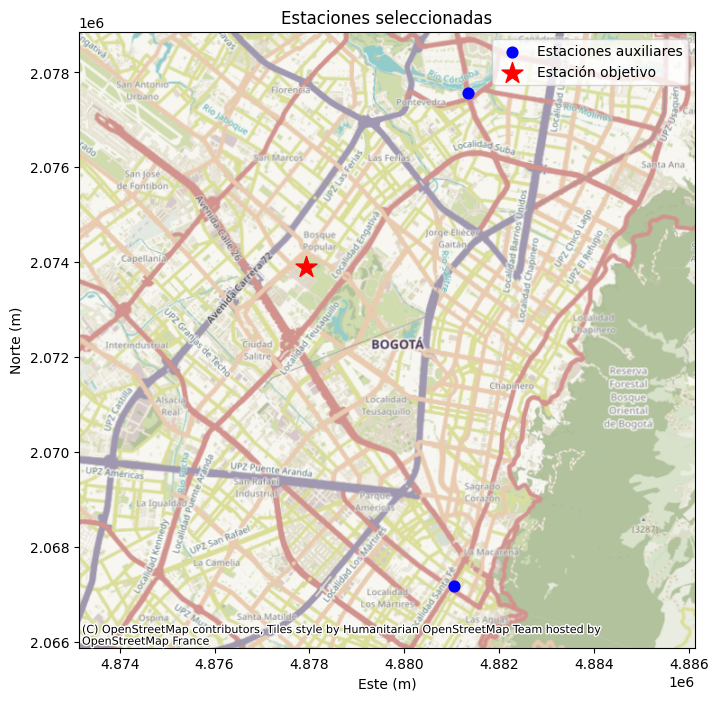

In [87]:
import contextily as cx

fig, ax = plt.subplots(figsize=(10, 8))


# Estaciones seleccionadas
estaciones_plot = info_geometrica_estaciones[
    info_geometrica_estaciones["CODIGO"].isin(
        ESTACIONES_SELECCIONADAS
    )
]


# Estaciones auxiliares
estaciones_aux_plot = info_geometrica_estaciones[
    info_geometrica_estaciones["CODIGO"].isin(
        ESTACIONES_AUXILIARES
    )
]

estaciones_aux_plot.plot(
    ax=ax,
    marker="o",
    color="blue",
    label="Estaciones auxiliares",
    markersize=60,
    zorder=2
)


# Estación objetivo
estacion_obj_plot = info_geometrica_estaciones[
    info_geometrica_estaciones["CODIGO"] == ESTACION_OBJETIVO
].iloc[0]

ax.scatter(
    estacion_obj_plot.geometry.x,
    estacion_obj_plot.geometry.y,
    marker="*",
    color="red",
    label="Estación objetivo",
    s=250,
    zorder=3
)


# Ajustar extensión del mapa
xmin, ymin, xmax, ymax = estaciones_plot.total_bounds

ancho = xmax - xmin
alto = ymax - ymin

lado = max(ancho, alto)

centro_x = (xmin + xmax) / 2
centro_y = (ymin + ymax) / 2

margen = 1.25

ax.set_xlim(
    centro_x - lado / 2 * margen,
    centro_x + lado / 2 * margen
)

ax.set_ylim(
    centro_y - lado / 2 * margen,
    centro_y + lado / 2 * margen
)


# Mapa base
cx.add_basemap(
    ax,
    crs=info_geometrica_estaciones.crs,
    source=cx.providers.OpenStreetMap.HOT
)


ax.set_title("Estaciones seleccionadas")
ax.set_xlabel("Este (m)")
ax.set_ylabel("Norte (m)")
ax.legend()

plt.show()

El mapa permite verificar visualmente que las estaciones forman un conjunto espacialmente próximo dentro del área de estudio.

Se extrae de `df_wide` el periodo 2004–2015 y únicamente las tres estaciones seleccionadas. A diferencia del subconjunto de 1.789 días completos, aquí se conservan **todos los días del calendario y sus `NaN` naturales**.

In [88]:
df_periodo_seleccionado = df_wide.loc[
    FECHA_INICIO:FECHA_FIN,
    ESTACIONES_SELECCIONADAS
].copy()

Se crea `df_periodo_seleccionado`, que constituye la salida principal para el Notebook 03. Mantener los `NaN` naturales es necesario para distinguir posteriormente los faltantes originales de los valores que se ocultarán artificialmente.

Se comprueba el tamaño del periodo exportable, el número de valores nulos por estación y las fechas mínima y máxima.

In [89]:
print(df_periodo_seleccionado.shape)

print(
    df_periodo_seleccionado.isna().sum()
)

print(
    df_periodo_seleccionado.index.min(),
    df_periodo_seleccionado.index.max()
)

(4383, 3)
CodigoEstacion
21205710     690
21201230    1499
21201600    1915
dtype: int64
2004-01-01 00:00:00 2015-12-31 00:00:00


El conjunto contiene **4.383 días y 3 estaciones**, desde `2004-01-01` hasta `2015-12-31`. Los faltantes naturales son **690** para `21205710`, **1.499** para `21201230` y **1.915** para `21201600`. Estos `NaN` se conservan deliberadamente y serán identificados explícitamente en el Notebook 03.

Se guarda el periodo seleccionado en formato Parquet.

In [90]:
df_periodo_seleccionado.to_parquet(
    PROJECT_ROOT / "data" / "intermediate" / "precipitacion_periodo_seleccionado.parquet"
)

No se genera salida visual. El archivo `precipitacion_periodo_seleccionado.parquet` queda almacenado en `data/intermediate` y será la entrada principal de precipitación del Notebook 03.

Se filtra el catálogo de estaciones para conservar únicamente los metadatos de la estación objetivo y las dos auxiliares.

In [91]:
df_estaciones_seleccionadas = (
    estaciones_candidatas.loc[
        estaciones_candidatas["CODIGO"].isin(
            ESTACIONES_SELECCIONADAS
        )
    ]
    .copy()
)

Se crea `df_estaciones_seleccionadas`, manteniendo los atributos descriptivos y la geometría provenientes del Notebook 01.

Se añade una columna booleana que identifica qué estación cumple el rol de objetivo y se guarda el conjunto como GeoJSON.

In [92]:
df_estaciones_seleccionadas["Objetivo"] = df_estaciones_seleccionadas["CODIGO"] == ESTACION_OBJETIVO

df_estaciones_seleccionadas.to_file(
    PROJECT_ROOT / "data" / "intermediate" / "estaciones_seleccionadas.geojson",
    driver="GeoJSON"
)


df_estaciones_seleccionadas

,CODIGO,nombre,CATEGORIA,TECNOLOGIA,ESTADO,FECHA_INST,altitud,latitud,longitud,DEPARTAMEN,...,d_AREA_HID,d_ZONA_HID,d_CORRIENT,d_SUBZONA_,distancia_m,distancia_km,FECHA_INST_MOD,FECHA_SUSP_MOD,geometry,Objetivo
3,21205710,JARDIN BOTANICO [21205710],CP,"TEST001,TEST003",ESTA001,1974-09-15,2552.0,4.667867,-74.101034,11.0,...,Magdalena Cauca,Alto Magdalena,None,Río Bogotá,2709.989675,2.709990,1974-09-15,NaT,POINT (4877927.545 2073889.531),True
8,21201230,ENMANUEL D' ALZON [21201230],PM,TEST003,ESTA002,1974-04-15,2520.0,4.701125,-74.070306,11.0,...,Magdalena Cauca,Alto Magdalena,None,Río Bogotá,4167.428588,4.167429,1974-04-15,2025-11-24,POINT (4881340.437 2077559.696),False
17,21201600,SEDE IDEAM KRA 10 [21201600],PG,TEST003,ESTA002,1986-09-14,2685.0,4.607111,-74.072889,11.0,...,Magdalena Cauca,Alto Magdalena,None,Río Bogotá,6302.648333,6.302648,1986-09-14,2019-05-03,POINT (4881038.215 2067170.438),False


La tabla confirma tres estaciones seleccionadas y marca `21205710` con `Objetivo = True`. El archivo `estaciones_seleccionadas.geojson` conserva geometría, altitud y demás metadatos espaciales para utilizarlos en el diseño experimental.

Se guarda en formato Parquet el resumen anual de disponibilidad de la configuración seleccionada.

In [93]:
resumen_A_2024.to_parquet(
    PROJECT_ROOT / "data" / "intermediate" / "disponibilidad_periodo_seleccionado.parquet"
)

## 15 - Síntesis metodológica para la memoria del TFM

A partir de los registros diarios descargados desde DHIME se construyó un calendario continuo para cada estación, conservando como valores faltantes (`NaN`) aquellas fechas sin observación en los archivos originales. Los registros explícitos de precipitación igual a cero se mantuvieron como observaciones válidas y no fueron confundidos con datos faltantes.

La selección del conjunto de estudio consideró cobertura temporal, solapamiento diario, continuidad anual y relaciones espaciales entre estaciones. Como resultado se seleccionó la estación `21205710` como objetivo y las estaciones `21201230` y `21201600` como auxiliares para el periodo comprendido entre 2004 y 2015.

En dicho intervalo se identificaron 1.789 días con observaciones simultáneas en las tres estaciones.
